In [3]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

In [5]:
import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt

# Grafo
G = nx.DiGraph()
G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

edges = [
    ("A","B", 7, 6),  ("A","C", 8, 6),
    ("B","C",-1, 6),  ("B","D", 4, 6), ("B","E", 1, 6), ("B","F", 5, 6),
    ("C","F", 3, 6),
    ("D","F", 1, 6),
    ("E","C",-2, 6), ("E","D", 0, 6),
    ("F","E", 3, 6),
]
for i, j, cost, cap in edges:
    G.add_edge(i, j, cost=cost, cap=cap)

# b[v]
b = {n: 0 for n in G.nodes}
b.update({
    "A": -4,
    "B": -4,
    "C":  6,
    "D": 10,
    "E": -4,
    "F": -4,
})


# Modello
m = gp.Model("mcf")

# Variabili
x = m.addVars(G.edges, vtype=GRB.INTEGER, lb=0, name="x")

# Vincoli di bilanciamento
for v in G.nodes:
    inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
    outflow = gp.quicksum(x[v, j] for j in G.successors(v))
    m.addConstr(inflow - outflow == b[v], name=f"balance[{v}]")

# Vincoli di capacità
for (i, j) in G.edges:
    m.addConstr(x[i, j] <= G[i][j]["cap"], name=f"capacity[{i},{j}]")

# O.f.
m.setObjective(gp.quicksum(G[i][j]["cost"] * x[i, j] for (i, j) in G.edges), GRB.MINIMIZE)


# Ottimizza
m.optimize()

# Risultati

archi_con_flusso = []
if m.status == GRB.OPTIMAL:
    print(f"Costo totale = {m.objVal:.6g}")
    print("\nFlussi sugli archi (x[i,j] > 0):")
    for (i, j) in G.edges:
        if x[i, j].X > 1e-9:
            archi_con_flusso.append((i, j))
            print(f"  x[{i},{j}] = {x[i,j].X:.6g}")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Ubuntu 22.04.4 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 17 rows, 11 columns and 33 nonzeros
Model fingerprint: 0xde8f8205
Variable types: 0 continuous, 11 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 8e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+00, 1e+01]
Found heuristic solution: objective 56.0000000
Presolve removed 17 rows and 11 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 2 available processors)

Solution count 2: 48 56 

Optimal solution found (tolerance 1.00e-04)
Best objective 4.800000000000e+01, best bound 4.800000000000e+01, gap 0.0000%
Costo totale = 48

Flussi sugli archi (x[i,j] >

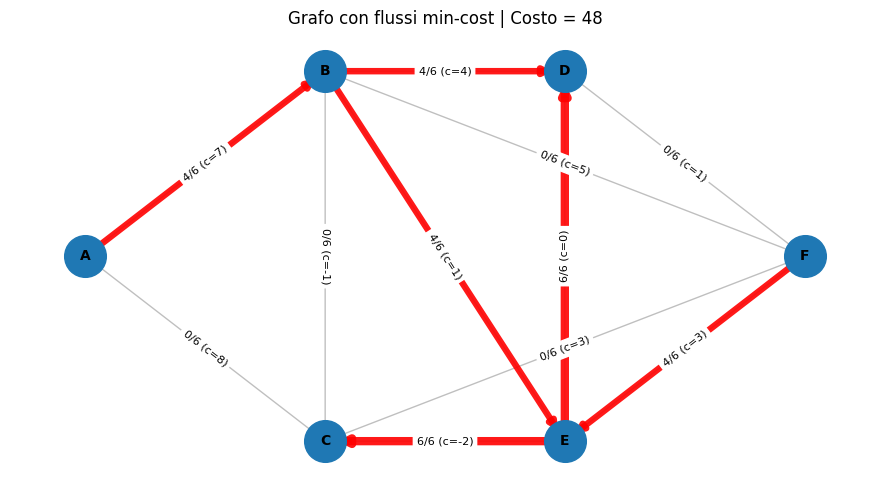

In [7]:

# Visualizzazione
pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(9, 5))

nx.draw_networkx_edges(G, pos, edgelist=list(G.edges), width=1.0, alpha=0.25, arrows=True)

if archi_con_flusso:
    flows = [x[i, j].X for (i, j) in archi_con_flusso]
    fmax = max(flows) if flows else 1.0
    widths = [2.0 + 4.0 * (x[i, j].X / fmax) for (i, j) in archi_con_flusso]
    nx.draw_networkx_edges(G, pos, edgelist=archi_con_flusso, width=widths, alpha=0.9, arrows=True, edge_color="r")

nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_labels = {}
for (i, j) in G.edges:
    flow = x[i, j].X if m.status == GRB.OPTIMAL else 0.0
    cap  = G[i][j]["cap"]
    cost = G[i][j]["cost"]
    if flow > 1e-9:
        edge_labels[(i, j)] = f"{flow:.0f}/{cap} (c={cost})"
    else:
        edge_labels[(i, j)] = f"0/{cap} (c={cost})"
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

title = "Grafo con flussi min-cost"
if m.status == GRB.OPTIMAL:
    title += f" | Costo = {m.objVal:.3g}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()